In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import Image, display

df = pd.read_csv("spotify_top_1000_tracks.csv")

student_name = "YOUR NAME"
student_id = "YOUR STUDENT ID"

color1 = "#1f77b4"

print("Dataset loaded successfully!")

Dataset loaded successfully!


Animation saved successfully!


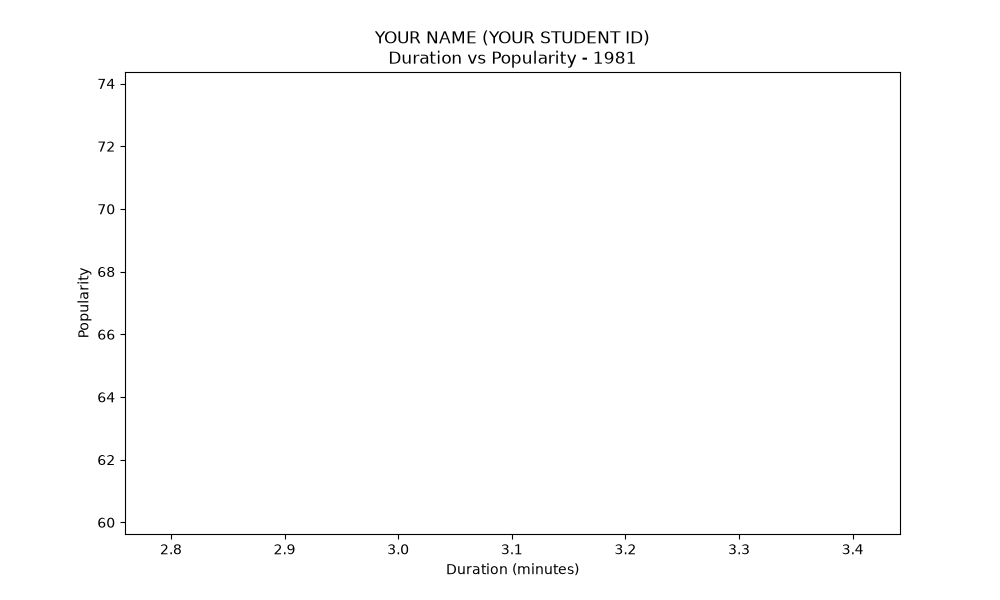

In [2]:
# Additional Exercise 3: Animated Density Map

animation_df = df.dropna(
    subset=['release_date', 'duration_min', 'popularity']
).copy()

animation_df['year'] = pd.to_datetime(
    animation_df['release_date'],
    errors='coerce'
).dt.year

animation_df = animation_df.dropna(subset=['year'])
animation_df['year'] = animation_df['year'].astype(int)

years = sorted(animation_df['year'].unique())

custom_cmap = LinearSegmentedColormap.from_list(
    'student_cmap',
    ['white', color1]
)

fig, ax = plt.subplots(figsize=(10, 6))

def update(frame):
    ax.clear()

    current_year = years[frame]

    year_data = animation_df[
        animation_df['year'] <= current_year
    ]

    ax.hexbin(
        year_data['duration_min'],
        year_data['popularity'],
        gridsize=20,
        cmap=custom_cmap,
        mincnt=1
    )

    ax.set_title(
        f"{student_name} ({student_id})\n"
        f"Duration vs Popularity - {current_year}"
    )

    ax.set_xlabel("Duration (minutes)")
    ax.set_ylabel("Popularity")

    return []

ani = animation.FuncAnimation(
    fig,
    update,
    frames=len(years),
    interval=500,
    repeat=False
)

ani.save(
    "animated_density_map.gif",
    writer=animation.PillowWriter(fps=2)
)

plt.close(fig)

print("Animation saved successfully!")

display(Image(filename="animated_density_map.gif"))